In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
data=pd.read_csv(r"C:\Users\Lenovo\Downloads\hr_employee_attrition.csv")
data

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [5]:
data.describe(include='all')

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


In [6]:
#missing values and duplicates
print(data.isnull().sum().sum())
print(data.duplicated().sum())

0
0


In [7]:
#drop constant columns and the employee id (no information for the model)
data=data.drop(columns=['EmployeeCount','Over18','StandardHours','EmployeeNumber'])
data['Attrition_bin']=(data['Attrition']=='Yes').astype(int)   # 1 = employee left

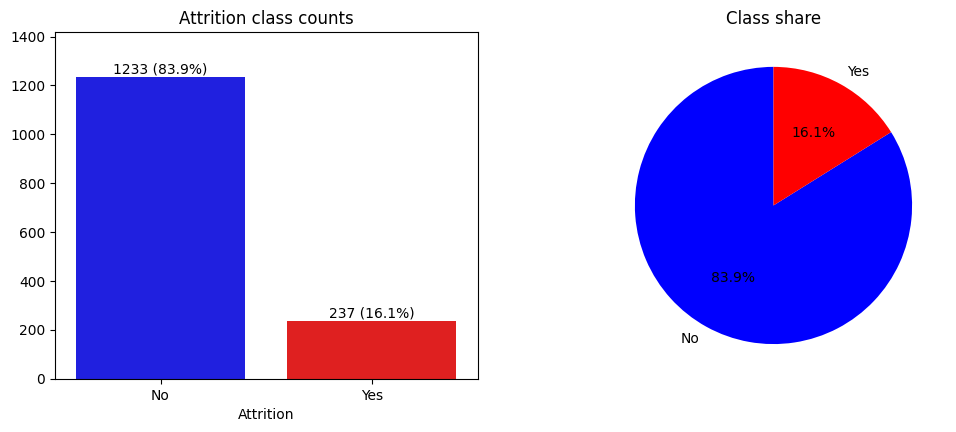

imbalance ratio (stayed : left) = 5.2 : 1


In [8]:
#class imbalance: how many employees stayed vs left
counts=data['Attrition'].value_counts()
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.barplot(x=counts.index,y=counts.values,hue=counts.index,palette={'No':'blue','Yes':'red'},legend=False,ax=ax[0])
for i,v in enumerate(counts.values):
    ax[0].text(i,v+15,f'{v} ({v/len(data):.1%})',ha='center')
ax[0].set_ylim(0,counts.max()*1.15)
ax[0].set_title('Attrition class counts')
ax[1].pie(counts.values,labels=counts.index,colors=['blue','red'],autopct='%1.1f%%',startangle=90)
ax[1].set_title('Class share')
plt.show()
print('imbalance ratio (stayed : left) =',round(counts['No']/counts['Yes'],1),': 1')

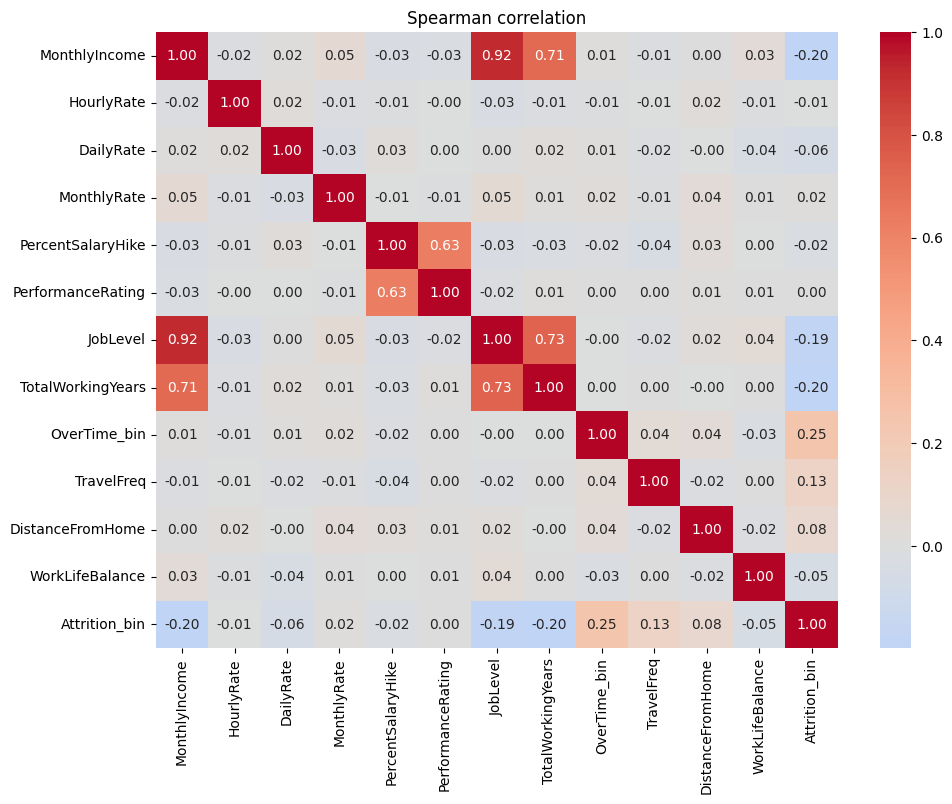

In [9]:
#correlation between salary, performance and working hours (overtime and travel used as workload)
corr_data=data.copy()
corr_data['OverTime_bin']=(corr_data['OverTime']=='Yes').astype(int)
corr_data['TravelFreq']=corr_data['BusinessTravel'].map({'Non-Travel':0,'Travel_Rarely':1,'Travel_Frequently':2})
cols=['MonthlyIncome','HourlyRate','DailyRate','MonthlyRate','PercentSalaryHike','PerformanceRating','JobLevel',
      'TotalWorkingYears','OverTime_bin','TravelFreq','DistanceFromHome','WorkLifeBalance','Attrition_bin']
plt.figure(figsize=(11,8))
sns.heatmap(corr_data[cols].corr(method='spearman'),annot=True,fmt='.2f',cmap='coolwarm',center=0)
plt.title('Spearman correlation')
plt.show()

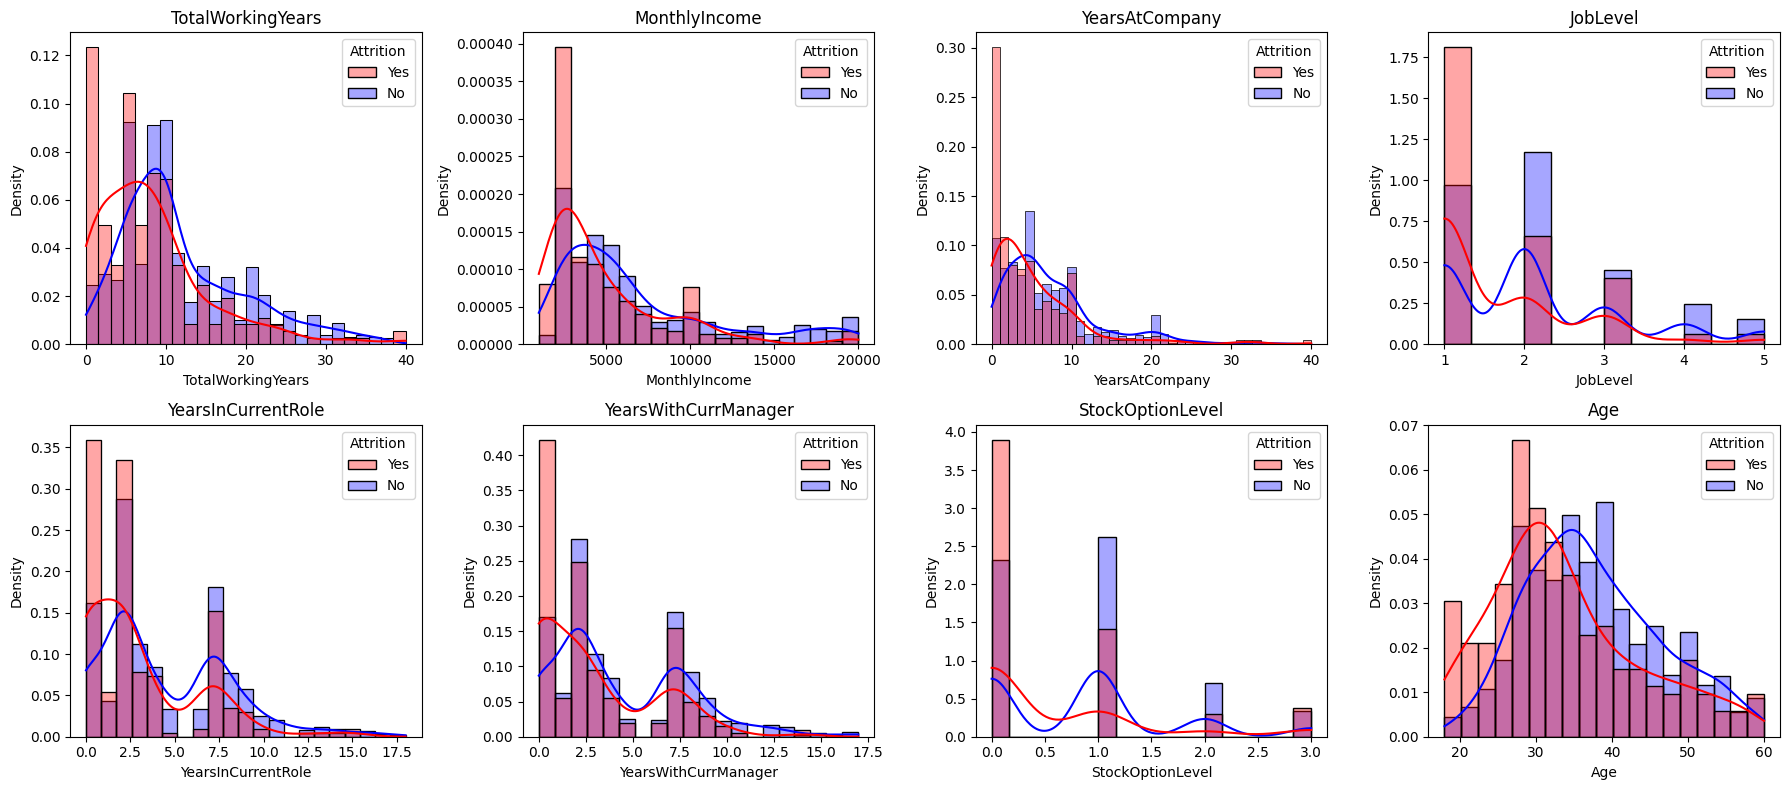

In [10]:
#distributions of the 8 numeric features most related to attrition
num_cols=[c for c in data.select_dtypes('number').columns if c!='Attrition_bin']
top=data[num_cols].corrwith(data['Attrition_bin'],method='spearman').abs().sort_values(ascending=False).head(8).index
fig,axes=plt.subplots(2,4,figsize=(18,8))
for ax,c in zip(axes.ravel(),top):
    sns.histplot(data=data,x=c,hue='Attrition',kde=True,stat='density',common_norm=False,
                 palette={'No':'blue','Yes':'red'},alpha=0.35,ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [11]:
#count outliers with the 1.5 x IQR rule
cont_cols=[c for c in num_cols if data[c].nunique()>10]
q1=data[cont_cols].quantile(.25)
q3=data[cont_cols].quantile(.75)
iqr=q3-q1
outliers=((data[cont_cols]<q1-1.5*iqr)|(data[cont_cols]>q3+1.5*iqr)).sum().sort_values(ascending=False)
outliers

MonthlyIncome              114
YearsSinceLastPromotion    107
YearsAtCompany             104
TotalWorkingYears           63
YearsInCurrentRole          21
YearsWithCurrManager        14
DailyRate                    0
Age                          0
HourlyRate                   0
DistanceFromHome             0
PercentSalaryHike            0
MonthlyRate                  0
dtype: int64

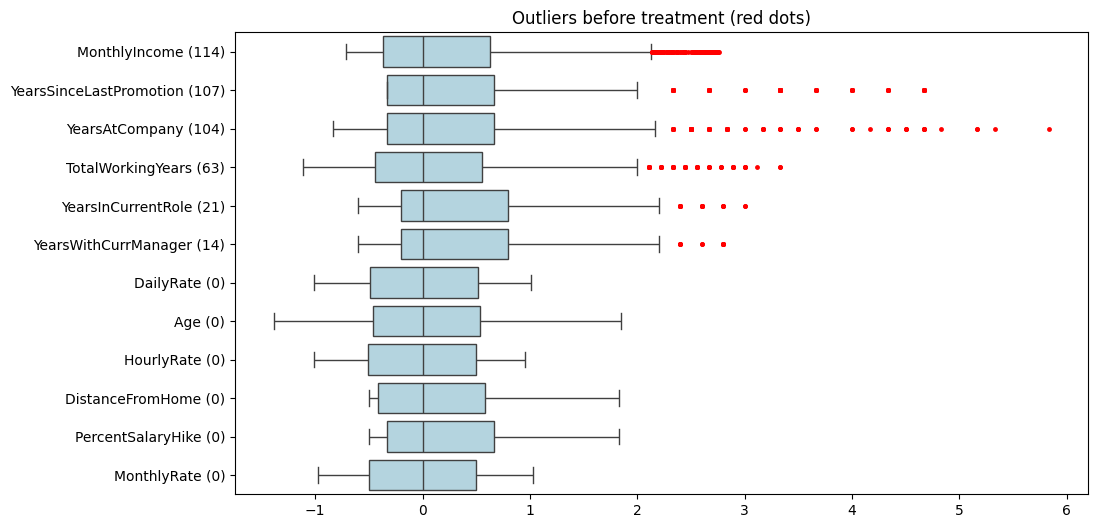

In [12]:
#outlier plot before treatment (values scaled by median and IQR so all features share one axis)
rob=(data[cont_cols]-data[cont_cols].median())/iqr.replace(0,np.nan)
plt.figure(figsize=(11,6))
sns.boxplot(data=rob[outliers.index],orient='h',color='lightblue',
            flierprops=dict(marker='o',markerfacecolor='red',markeredgecolor='none',markersize=3.5))
plt.yticks(range(len(outliers)),[f'{c} ({n})' for c,n in outliers.items()])
plt.title('Outliers before treatment (red dots)')
plt.show()

In [13]:
#features and target
y=data['Attrition_bin']
X=data.drop(columns=['Attrition','Attrition_bin'])

In [14]:
#feature engineering: pay relative to seniority, experience and age + career progress ratios
#the +1 prevents dividing by zero
X['IncomePerJobLevel']=X.MonthlyIncome/X.JobLevel
X['IncomePerYearExp']=X.MonthlyIncome/(X.TotalWorkingYears+1)
X['IncomePerAge']=X.MonthlyIncome/X.Age
#checking if the employee is stuck in the same jobs/ Hoping rate
X['TenureRatio']=X.YearsAtCompany/(X.TotalWorkingYears+1)
X['AvgYearsPerCompany']=X.TotalWorkingYears/(X.NumCompaniesWorked+1)
X['PromotionGapRatio']=X.YearsSinceLastPromotion/(X.YearsAtCompany+1)
X['RoleStagnation']=X.YearsInCurrentRole/(X.YearsAtCompany+1)
X['ManagerTenureRatio']=X.YearsWithCurrManager/(X.YearsAtCompany+1)

In [15]:
#feature engineering: satisfaction scores and workload (overtime) combinations
sat_cols=['EnvironmentSatisfaction','JobSatisfaction','RelationshipSatisfaction','WorkLifeBalance','JobInvolvement']
X['SatisfactionMean']=X[sat_cols].mean(axis=1)
X['LowSatisfactionCnt']=(X[sat_cols]<=2).sum(axis=1)
#Checking for overtime with being single or traveling
ot=(X.OverTime=='Yes').astype(int)
X['OT_x_Single']=ot*(X.MaritalStatus=='Single').astype(int)
X['OT_x_TravelFreq']=ot*(X.BusinessTravel=='Travel_Frequently').astype(int)
X['OT_x_LowWLB']=ot*(X.WorkLifeBalance<=2).astype(int)
X['WorkloadStress']=ot+X.BusinessTravel.map({'Non-Travel':0,'Travel_Rarely':1,'Travel_Frequently':2})+(X.DistanceFromHome>15).astype(int)

In [16]:
#drop the 3 pay-rate columns (no relation to attrition) and one-hot copy the ordinal scores , tells the model that ex:joblevel 1 doesnot behave like other levels
X=X.drop(columns=['DailyRate','HourlyRate','MonthlyRate'])
for c in ['JobLevel','StockOptionLevel','JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance','JobInvolvement']:
    X[c+'_cat']=X[c].astype(str)

In [17]:
#log1p on skewed features (reduces the effect of outliers) applied for skew > 0.75
skewed=[c for c in X.columns if pd.api.types.is_numeric_dtype(X[c]) and X[c].nunique()>10 and X[c].min()>=0 and abs(X[c].skew())>0.75]
for c in skewed:
    X[c+'_log']=np.log1p(X[c])
    X=X.drop(columns=c)
print(skewed)

['DistanceFromHome', 'MonthlyIncome', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'IncomePerYearExp', 'IncomePerAge', 'AvgYearsPerCompany', 'PromotionGapRatio']


In [18]:
from sklearn.model_selection import train_test_split,GridSearchCV,RepeatedStratifiedKFold,StratifiedKFold,cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,
                             classification_report,precision_recall_curve,roc_curve,confusion_matrix,ConfusionMatrixDisplay)

In [19]:
#80/20 split keeping the same share of leavers in both parts
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
print(X_train.shape,X_test.shape,round(y_train.mean(),3),round(y_test.mean(),3))
#test set has only 47 leavers

(1176, 47) (294, 47) 0.162 0.16


In [20]:
#outlier handling: cap values outside Q1-1.5*IQR / Q3+1.5*IQR 
#(limits learned on training data only, no rows deleted) the class learns the fences so there is no leak
class Winsorizer(BaseEstimator,TransformerMixin):
    def __init__(self,k=1.5):
        self.k=k
    def fit(self,X,y=None):
        q1,q3=np.percentile(np.asarray(X,dtype=float),[25,75],axis=0)
        self.lo_,self.hi_=q1-self.k*(q3-q1),q3+self.k*(q3-q1)
        return self
    def transform(self,X):
        return np.clip(np.asarray(X,dtype=float),self.lo_,self.hi_)
    def get_feature_names_out(self,input_features=None):
        return np.asarray(input_features,dtype=object)

In [21]:
#preprocessing: cap + scale continuous, scale the other numbers, one-hot the text columns
cont=[c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c]) and X_train[c].nunique()>10]
other=[c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c]) and c not in cont]
cat=[c for c in X_train.columns if c not in cont+other]
prep=ColumnTransformer([('cont',Pipeline([('cap',Winsorizer()),('scale',StandardScaler())]),cont),
                        ('other',StandardScaler(),other),
                        ('cat',OneHotEncoder(drop='if_binary',handle_unknown='ignore'),cat)])

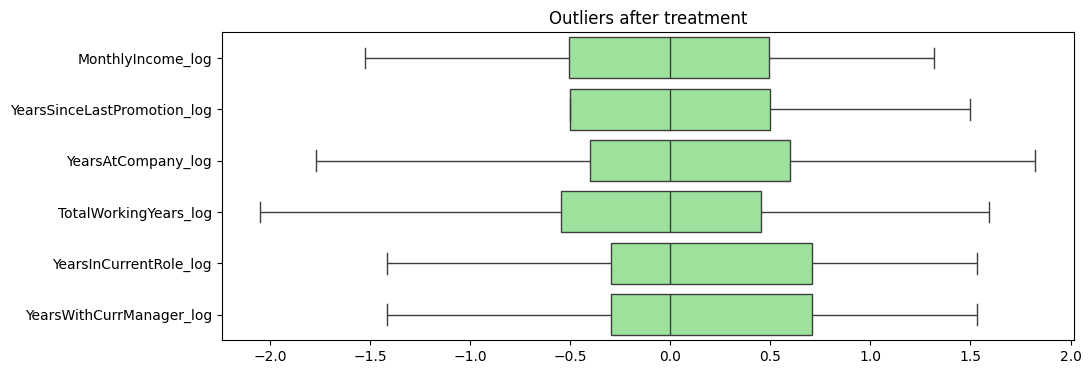

In [22]:
#outlier plot after treatment (log1p + capping) for the features that had outliers
feats=[c+'_log' if c+'_log' in X_train else c for c in outliers[outliers>0].index if c+'_log' in X_train or c in X_train]
capped=pd.DataFrame(Winsorizer().fit_transform(X_train[feats]),columns=feats)
rob=(capped-capped.median())/(capped.quantile(.75)-capped.quantile(.25)).replace(0,np.nan)
plt.figure(figsize=(11,4))
sns.boxplot(data=rob,orient='h',color='lightgreen',
            flierprops=dict(marker='o',markerfacecolor='red',markeredgecolor='none',markersize=3.5))
plt.title('Outliers after treatment')
plt.show()

In [ ]:
#Logistic Regression: grid search scored by PR-AUC (best for an imbalanced target) 4 parts are train and 5th test
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=42)
lr_pipe=Pipeline([('prep',prep),('clf',LogisticRegression(solver='liblinear',max_iter=5000,random_state=42))])
lr_grid={'clf__penalty':['l1','l2'],'clf__C':[0.01,0.03,0.1,0.3,1,3,10],'clf__class_weight':[None,'balanced']}#makes the leavers count more
lr_gs=GridSearchCV(lr_pipe,lr_grid,scoring='average_precision',cv=cv,n_jobs=-1).fit(X_train,y_train)
print(lr_gs.best_params_,round(lr_gs.best_score_,4))

{'clf__C': 1, 'clf__class_weight': None, 'clf__penalty': 'l1'} 0.7073


In [24]:
#SVC: grid search scored by PR-AUC
svc_pipe=Pipeline([('prep',prep),('clf',SVC(random_state=42))])
svc_grid=[{'clf__kernel':['rbf'],'clf__C':[0.3,1,3,10],'clf__gamma':['scale',0.001,0.003,0.01,0.03],'clf__class_weight':[None,'balanced']},
          {'clf__kernel':['linear'],'clf__C':[0.003,0.01,0.03,0.1,1],'clf__class_weight':[None,'balanced']}]
svc_gs=GridSearchCV(svc_pipe,svc_grid,scoring='average_precision',cv=cv,n_jobs=-1).fit(X_train,y_train)
print(svc_gs.best_params_,round(svc_gs.best_score_,4))

{'clf__C': 0.1, 'clf__class_weight': None, 'clf__kernel': 'linear'} 0.7057


In [25]:
#best decision threshold per model: the one with the highest leaver F1 on out-of-fold training predictions
best={'Logistic Regression':lr_gs.best_estimator_,'SVC':svc_gs.best_estimator_}
thr={}
for name,model in best.items():
    oof=cross_val_predict(model,X_train,y_train,cv=StratifiedKFold(5,shuffle=True,random_state=42),method='decision_function',n_jobs=-1)
    p,r,t=precision_recall_curve(y_train,oof)
    f1=2*p[:-1]*r[:-1]/np.clip(p[:-1]+r[:-1],1e-9,None)
    thr[name]=t[np.argmax(f1)]
    print(name,'threshold',round(thr[name],3),'out-of-fold F1',round(f1.max(),3))

Logistic Regression threshold -0.678 out-of-fold F1 0.653
SVC threshold -0.267 out-of-fold F1 0.644


In [26]:
#test set metrics of both models (Yes = employee left)
scores={n:m.decision_function(X_test) for n,m in best.items()}
pred={n:(scores[n]>=thr[n]).astype(int) for n in best}
pd.DataFrame({n:{'Accuracy':accuracy_score(y_test,pred[n]),'Precision (Yes)':precision_score(y_test,pred[n]),
                 'Recall (Yes)':recall_score(y_test,pred[n]),'F1 (Yes)':f1_score(y_test,pred[n]),
                 'ROC-AUC':roc_auc_score(y_test,scores[n]),'PR-AUC':average_precision_score(y_test,scores[n])} for n in best}).T.round(3)

,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),ROC-AUC,PR-AUC
Logistic Regression,0.854,0.543,0.532,0.538,0.838,0.600
SVC,0.867,0.605,0.489,0.541,0.825,0.591


In [27]:
#classification reports
for n in best:
    print('=====',n,'=====')
    print(classification_report(y_test,pred[n],target_names=['Stayed','Left'],digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

      Stayed      0.911     0.915     0.913       247
        Left      0.543     0.532     0.538        47

    accuracy                          0.854       294
   macro avg      0.727     0.723     0.725       294
weighted avg      0.852     0.854     0.853       294

===== SVC =====


              precision    recall  f1-score   support

      Stayed      0.906     0.939     0.922       247
        Left      0.605     0.489     0.541        47

    accuracy                          0.867       294
   macro avg      0.756     0.714     0.732       294
weighted avg      0.858     0.867     0.862       294



In [ ]:
#model selection on training cross-validation (not the test set): best PR-AUC, and if the models are within 1 standard error the simpler one wins
cv_ap={'Logistic Regression':lr_gs.best_score_,'SVC':svc_gs.best_score_}
leader=max(cv_ap,key=cv_ap.get)
gs=lr_gs if leader=='Logistic Regression' else svc_gs
se=gs.cv_results_['std_test_score'][gs.best_index_]/np.sqrt(cv.get_n_splits())
winner='Logistic Regression' if cv_ap['Logistic Regression']>=cv_ap[leader]-se else leader
print('selected model:',winner,cv_ap)
#the models predicts the risk of leaving 

selected model: Logistic Regression {'Logistic Regression': np.float64(0.7073425719161507), 'SVC': np.float64(0.7056887245459749)}


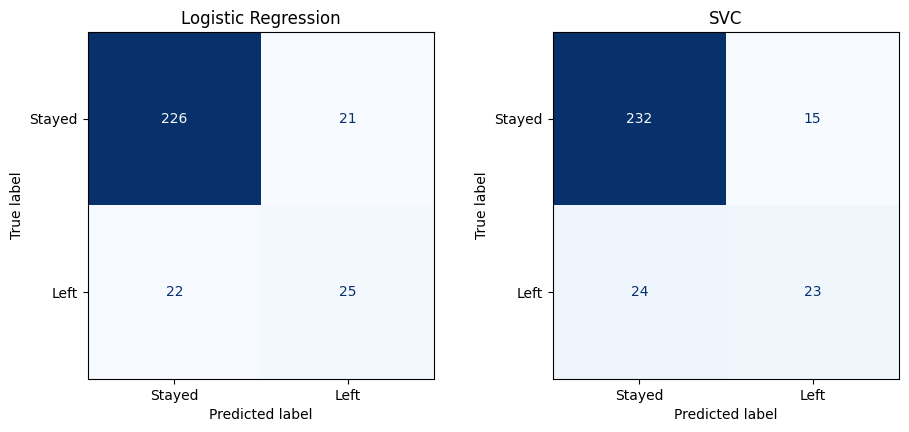

In [29]:
#confusion matrices
fig,ax=plt.subplots(1,2,figsize=(11,4.5))
for a,n in zip(ax,best):
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred[n]),display_labels=['Stayed','Left']).plot(ax=a,cmap='Blues',colorbar=False)
    a.set_title(n)
plt.show()

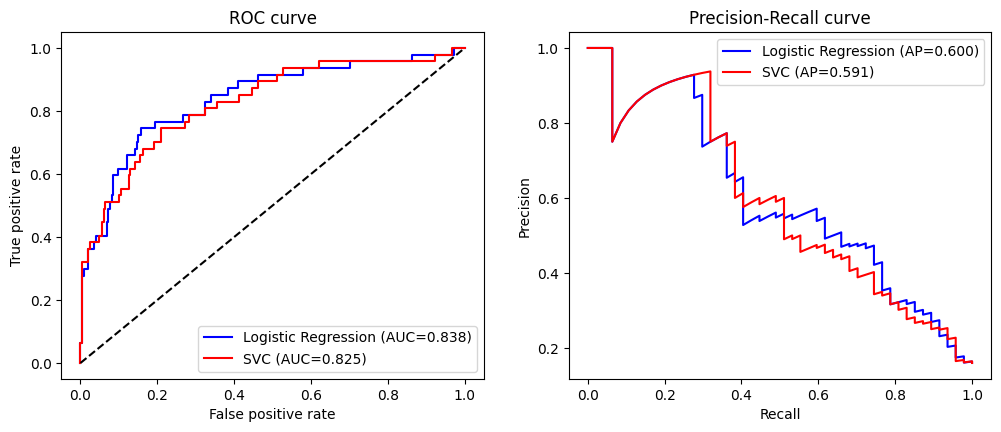

In [30]:
#ROC and precision-recall curves shows how the models behaves across all possible cutoffs
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for n,c in zip(best,['blue','red']):
    fpr,tpr,_=roc_curve(y_test,scores[n])
    ax[0].plot(fpr,tpr,color=c,label=f'{n} (AUC={roc_auc_score(y_test,scores[n]):.3f})')
    p,r,_=precision_recall_curve(y_test,scores[n])
    ax[1].plot(r,p,color=c,label=f'{n} (AP={average_precision_score(y_test,scores[n]):.3f})')
ax[0].plot([0,1],[0,1],'k--')
ax[0].set_title('ROC curve'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend()
ax[1].set_title('Precision-Recall curve'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
plt.show()